# Python

In [1]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os
from rdflib import Graph, URIRef, Literal, Namespace
import networkx as nx
from pyvis.network import Network
import ipywidgets as widgets
from IPython.display import display, HTML, IFrame

## Visualizing polymers in a 3D lattice

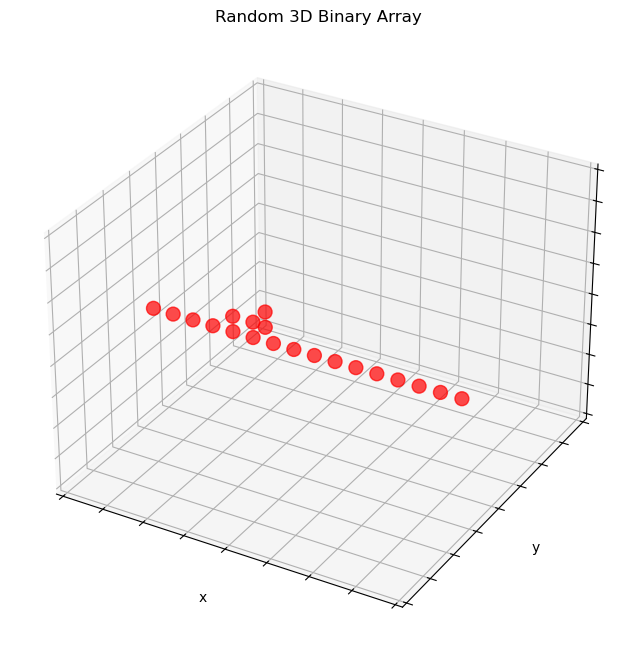

In [2]:
# import json data
dirname = "20250724/testpoly"
lattice = json.load(open("data/"+dirname+".json"))
lattice = np.array(lattice)


# Get coordinates where array == 1
coords1 = np.argwhere(lattice[..., -1] == 1)
coords2 = np.argwhere(lattice[..., -2] == 1)
x1, y1, z1 = coords1[:, 2], coords1[:, 1], coords1[:, 0]
x2, y2, z2 = coords2[:, 2], coords2[:, 1], coords2[:, 0]

# Scatterplot with circles at sites with a 1
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
# ax.scatter(x1, y1, z1, s=10, c='blue', marker='o', edgecolors='k', alpha=0.7)
ax.scatter(x2, y2, z2, s=100, c='red', marker='o', alpha=0.7)
ax.set_title('Random 3D Binary Array')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(0, lattice.shape[0])
ax.set_ylim(0, lattice.shape[0])
ax.set_zlim(0, lattice.shape[0])
ax.set_xticklabels('')
ax.set_yticklabels('')
ax.set_zticklabels('')
plt.show()

## Visualize context graph

In [18]:
# Install required packages if not already installed
get_ipython().system('pip install rdflib pyvis ipywidgets')

In [22]:
# Define a namespace for our knowledge graph
NS = Namespace("http://droplet.julia/")

def load_triples_to_rdflib(json_file):
    """Load triples from JSON and convert to RDFLib graph"""
    with open(json_file, 'r') as f:
        data = json.load(f)
    
    g = Graph()
    
    # Add all triples to the graph
    for s, p, o in data['triples']:
        # Convert to RDF terms
        subj = URIRef(NS[s])
        pred = URIRef(NS[p])
        
        # Check if object is likely a literal or a resource
        if o.startswith('"') or o.isdigit() or o in ["true", "false"]:
            obj = Literal(o)
        else:
            obj = URIRef(NS[o])
        
        g.add((subj, pred, obj))
    
    return g

def visualize_graph(g, output_file="knowledge_graph.html", height="750px", width="100%"):
    """Visualize the RDF graph using PyVis"""
    # Convert RDFLib graph to NetworkX
    G = nx.Graph()
    
    # Track unique nodes
    nodes = set()
    
    # Add edges to NetworkX graph
    for s, p, o in g:
        s_str = s.split('/')[-1]
        o_str = o.split('/')[-1] if isinstance(o, URIRef) else str(o)
        
        # Add nodes if they don't exist
        if s_str not in nodes:
            G.add_node(s_str)
            nodes.add(s_str)
        if o_str not in nodes:
            G.add_node(o_str)
            nodes.add(o_str)
        
        # Add edge with predicate as label
        p_str = p.split('/')[-1]
        G.add_edge(s_str, o_str, title=p_str)
    
    # Create PyVis network
    net = Network(height=height, width=width, notebook=True, directed=True, cdn_resources='remote')
    
    # Add nodes with different colors based on node type
    for node in G.nodes():
        if "!" in node:  # Functions
            net.add_node(node, label=node, color="#ADD8E6")  # Light blue
        elif "hasType" in node or "modifies" in node or "requires" in node:  # Predicates
            net.add_node(node, label=node, color="#FFFF99")  # Light yellow
        else:
            net.add_node(node, label=node, color="#90EE90")  # Light green
    
    # Add edges
    for edge in G.edges(data=True):
        net.add_edge(edge[0], edge[1], title=edge[2].get('title', ''))
    
    # Set physics layout options for better visualization
    net.set_options("""
    {
      "physics": {
        "hierarchicalRepulsion": {
          "centralGravity": 0.0,
          "springLength": 100,
          "springConstant": 0.01,
          "nodeDistance": 120
        },
        "maxVelocity": 50,
        "minVelocity": 0.1,
        "solver": "hierarchicalRepulsion"
      },
      "layout": {
        "hierarchical": {
          "enabled": false
        }
      }
    }
    """)
    
    # Save and display
    net.save_graph(output_file)
    return output_file

def query_graph(g, query_string):
    """Query the graph using SPARQL"""
    results = g.query(query_string)
    return results

# Path to the JSON file
json_file = "/home/tohme/.julia/dev/Droplet/src/ctx.json"

# Load the triples into an RDFLib graph
g = load_triples_to_rdflib(json_file)
print(f"Loaded {len(g)} triples")

# Create an interactive visualization
output_file = visualize_graph(g)

# Display in notebook
display(HTML(f'<h3>Interactive Knowledge Graph</h3>'))
display(IFrame(src=output_file, width='100%', height='600px'))

# Simple query interface
def run_query(query):
    try:
        results = query_graph(g, query)
        return results
    except Exception as e:
        return f"Error: {str(e)}"

# Example SPARQL query
example_query = """
PREFIX ns: <http://droplet.julia/>
SELECT ?function ?operation
WHERE {
    ?function ns:operation ?operation .
}
"""

print("\nExample SPARQL query:")
print(example_query)
print("\nResults:")
results = run_query(example_query)
for row in results:
    print(f"{row[0]} -> {row[1]}")

# Add a few example queries that users can try
query_examples = [
    """PREFIX ns: <http://droplet.julia/>
SELECT ?function ?arg
WHERE {
    ?function ns:hasArgument ?arg .
}""",
    """PREFIX ns: <http://droplet.julia/>
SELECT ?function
WHERE {
    ?function ns:modifies ?what .
    ?what ns:hasType "Vector" .
}"""
]

print("\nYou can try these additional queries:")
for i, q in enumerate(query_examples):
    print(f"\nExample {i+1}:")
    print(q)

# Create a simple query interface using ipywidgets
query_input = widgets.Textarea(
    value=example_query,
    placeholder='Enter SPARQL query here',
    description='Query:',
    disabled=False,
    rows=10,
    layout=widgets.Layout(width='100%')
)

execute_button = widgets.Button(description="Run Query")
output = widgets.Output()

def on_button_click(b):
    with output:
        output.clear_output()
        print("Running query...")
        results = run_query(query_input.value)
        print("Results:")
        for row in results:
            print(row)

execute_button.on_click(on_button_click)

print("\nInteractive Query Interface:")
display(query_input)
display(execute_button)
display(output)

# Add a function to modify the graph
def add_triple(subject, predicate, object_value):
    subj = URIRef(NS[subject])
    pred = URIRef(NS[predicate])
    
    if object_value.startswith('"') or object_value.isdigit() or object_value in ["true", "false"]:
        obj = Literal(object_value)
    else:
        obj = URIRef(NS[object_value])
    
    g.add((subj, pred, obj))
    return f"Added triple: {subject} - {predicate} -> {object_value}"

# Create a simple interface to add triples
subject_input = widgets.Text(description='Subject:', placeholder='Enter subject')
predicate_input = widgets.Text(description='Predicate:', placeholder='Enter predicate')
object_input = widgets.Text(description='Object:', placeholder='Enter object')
add_button = widgets.Button(description="Add Triple")
modify_output = widgets.Output()

def on_add_click(b):
    with modify_output:
        modify_output.clear_output()
        result = add_triple(subject_input.value, predicate_input.value, object_input.value)
        print(result)
        print(f"Graph now has {len(g)} triples")

add_button.on_click(on_add_click)

print("\nAdd Triple Interface:")
display(widgets.VBox([subject_input, predicate_input, object_input, add_button]))
display(modify_output)

# Function to export the modified graph
def export_graph(format='json-ld'):
    return g.serialize(format=format)

export_button = widgets.Button(description="Export Graph (JSON-LD)")
export_output = widgets.Output()

def on_export_click(b):
    with export_output:
        export_output.clear_output()
        serialized = export_graph()
        print("Graph exported:")
        print(serialized[:500] + "..." if len(serialized) > 500 else serialized)
        
        # Optionally save to file
        with open('exported_graph.jsonld', 'w') as f:
            f.write(serialized)
        print("\nSaved to 'exported_graph.jsonld'")

export_button.on_click(on_export_click)

print("\nExport Graph:")
display(export_button)
display(export_output)

http://droplet.julia/s.newPosi != s.bprev does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosi != s.bprev does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosj != s.bnext does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosj != s.bnext does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosi == s.bprev XOR s.newPosj == s.bnext does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosi == s.bprev XOR s.newPosj == s.bnext does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosi == s.bprev does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosi == s.bprev does not look like a valid URI, trying to serialize this will break.
http://droplet.julia/s.newPosj == s.bnext does not look like a

Loaded 81 triples



Example SPARQL query:

PREFIX ns: <http://droplet.julia/>
SELECT ?function ?operation
WHERE {
    ?function ns:operation ?operation .
}


Results:
http://droplet.julia/addBond! -> http://droplet.julia/Add two lattice sites and increase chain length
http://droplet.julia/kinkBond! -> http://droplet.julia/Change bond angle without changing length
http://droplet.julia/removeBond! -> http://droplet.julia/Remove lattice sites and decrease chain length

You can try these additional queries:

Example 1:
PREFIX ns: <http://droplet.julia/>
SELECT ?function ?arg
WHERE {
    ?function ns:hasArgument ?arg .
}

Example 2:
PREFIX ns: <http://droplet.julia/>
SELECT ?function
WHERE {
    ?function ns:modifies ?what .
    ?what ns:hasType "Vector" .
}

Interactive Query Interface:


Textarea(value='\nPREFIX ns: <http://droplet.julia/>\nSELECT ?function ?operation\nWHERE {\n    ?function ns:o…

Button(description='Run Query', style=ButtonStyle())

...


Add Triple Interface:


Output()


Export Graph:


Button(description='Export Graph (JSON-LD)', style=ButtonStyle())

Output()